# Autoencoders con Keras

https://blog.keras.io/building-autoencoders-in-keras.html

In [38]:
from keras.layers import Input, Dense, Concatenate, Conv2D, MaxPooling2D, UpSampling2D, AveragePooling2D
from keras.models import Model
from keras import regularizers

import matplotlib.pyplot as plt


In [48]:
# dimension de dominio intermedio
encoding_dim = 1

input_img = Input(shape=(28,28,1))
# ENCODER
x1 = Conv2D(encoding_dim,5,padding = 'SAME')(input_img) #activation='relu'
encoded = MaxPooling2D(4)(x1)
# DECODER

x2 = UpSampling2D(4, interpolation="bilinear")(encoded)

decoded = Conv2D(1,5,padding = 'SAME',activation='relu')(x2) # activation='sigmoid'

# AUTOENCODER
autoencoder = Model(input_img, decoded)
#autoencoder = Model(input_img, concat)

In [49]:
# Modelo de Luis
encoding_dim = 1

input_img = Input(shape=(28,28,1))
# ENCODER
x1 = Conv2D(encoding_dim,5,padding = 'SAME',kernel_regularizer=regularizers.l1(0.01))(input_img) #activation='relu'
encoded = AveragePooling2D(6)(x1)
x2 = Conv2D(encoding_dim,5,padding = 'SAME',kernel_regularizer=regularizers.l1(0.01))(encoded) #activation='relu'

# DECODER
x3 = UpSampling2D(7, interpolation="bilinear")(x2)
decoded = Conv2D(1,5,padding = 'SAME',activation='relu')(x3) # activation='sigmoid'

# AUTOENCODER
autoencoder = Model(input_img, decoded)
#autoencoder = Model(input_img, concat)

In [61]:
# Modelo de Samuel y Pablo y Jesus
encoding_dim = 1

input_img = Input(shape=(28,28,1))
# ENCODER
x1 = Conv2D(1,2,padding = 'SAME')(input_img) #activation='relu'
x2 = AveragePooling2D(2)(x1)
x3 = Conv2D(1,2,padding = 'SAME')(x2) #activation='relu'
encoded = AveragePooling2D(2)(x3)

# DECODER
x5 = UpSampling2D(2, interpolation="bicubic")(encoded)
x6 = Conv2D(1,2,padding = 'SAME')(x5) #activation='relu'
x7 = UpSampling2D(2, interpolation="bicubic")(x6)
decoded = Conv2D(1,2,padding = 'SAME')(x7) #activation='relu'

# AUTOENCODER
autoencoder = Model(input_img, decoded)
#autoencoder = Model(input_img, concat)

In [62]:
autoencoder.summary()

Model: "model_17"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_15 (InputLayer)       [(None, 28, 28, 1)]       0         
                                                                 
 conv2d_17 (Conv2D)          (None, 28, 28, 1)         5         
                                                                 
 average_pooling2d_2 (Avera  (None, 14, 14, 1)         0         
 gePooling2D)                                                    
                                                                 
 conv2d_18 (Conv2D)          (None, 14, 14, 1)         5         
                                                                 
 average_pooling2d_3 (Avera  (None, 7, 7, 1)           0         
 gePooling2D)                                                    
                                                                 
 up_sampling2d_7 (UpSamplin  (None, 14, 14, 1)         0  

In [63]:
# Modelo para el encoder
encoder = Model(input_img, encoded)
encoder.summary()

Model: "model_18"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_15 (InputLayer)       [(None, 28, 28, 1)]       0         
                                                                 
 conv2d_17 (Conv2D)          (None, 28, 28, 1)         5         
                                                                 
 average_pooling2d_2 (Avera  (None, 14, 14, 1)         0         
 gePooling2D)                                                    
                                                                 
 conv2d_18 (Conv2D)          (None, 14, 14, 1)         5         
                                                                 
 average_pooling2d_3 (Avera  (None, 7, 7, 1)           0         
 gePooling2D)                                                    
                                                                 
Total params: 10 (40.00 Byte)
Trainable params: 10 (40.00 

In [64]:
# Otra forma de hacer el decoder
decoder = Model(encoded, decoded)
decoder.summary()

Model: "model_19"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_16 (InputLayer)       [(None, 7, 7, 1)]         0         
                                                                 
 up_sampling2d_7 (UpSamplin  (None, 14, 14, 1)         0         
 g2D)                                                            
                                                                 
 conv2d_19 (Conv2D)          (None, 14, 14, 1)         5         
                                                                 
 up_sampling2d_8 (UpSamplin  (None, 28, 28, 1)         0         
 g2D)                                                            
                                                                 
 conv2d_20 (Conv2D)          (None, 28, 28, 1)         5         
                                                                 
Total params: 10 (40.00 Byte)
Trainable params: 10 (40.00 

In [65]:
autoencoder.compile(optimizer='adam', loss='mse',metrics=['mse','mae'])

In [66]:
# DATOS
from keras.datasets import mnist
import numpy as np
(x_train, _), (x_test, _) = mnist.load_data()

In [67]:
x_train.shape

(60000, 28, 28)

In [68]:

x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.
x_train = x_train.reshape((x_train.shape[0],x_train.shape[1],x_train.shape[2],1))
x_test = x_test.reshape((x_test.shape[0],x_test.shape[1],x_test.shape[2],1))
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [69]:
# ENTRENAMIENTO
hist = autoencoder.fit(x_train, x_train,
                epochs=20,
                batch_size=256,
                shuffle=True,
                validation_split=0.1)

Epoch 1/20
844/844 [==============================] - 9s 9ms/step - loss: 0.0531 - val_loss: 0.0360
Epoch 2/20
844/844 [==============================] - 6s 7ms/step - loss: 0.0347 - val_loss: 0.0346
Epoch 3/20
844/844 [==============================] - 7s 8ms/step - loss: 0.0338 - val_loss: 0.0338
Epoch 4/20
844/844 [==============================] - 6s 7ms/step - loss: 0.0332 - val_loss: 0.0335
Epoch 5/20
844/844 [==============================] - 7s 8ms/step - loss: 0.0329 - val_loss: 0.0332
Epoch 6/20
844/844 [==============================] - 7s 8ms/step - loss: 0.0328 - val_loss: 0.0331
Epoch 7/20
844/844 [==============================] - 6s 8ms/step - loss: 0.0327 - val_loss: 0.0331
Epoch 8/20
844/844 [==============================] - 6s 8ms/step - loss: 0.0327 - val_loss: 0.0331
Epoch 9/20
844/844 [==============================] - 10s 12ms/step - loss: 0.0327 - val_loss: 0.0331
Epoch 10/20
844/844 [==============================] - 9s 10ms/step - loss: 0.0327 - val_loss: 0.0

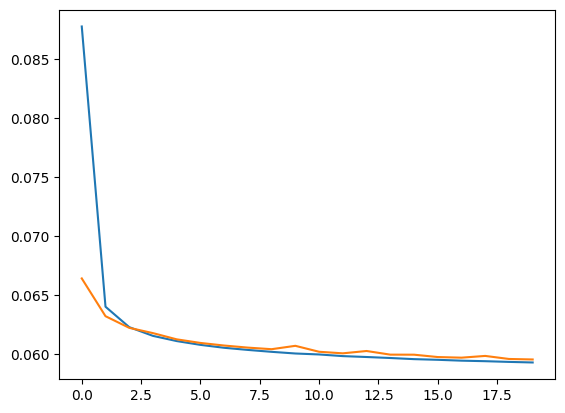

In [58]:
plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])

In [59]:
# APLICACION EN TEST
encoded_imgs = encoder.predict(x_test)
decoded_imgs = decoder.predict(encoded_imgs)

# Mismo que
# decoded_imgs = autoencoder.predict(x_test)

313/313 [==============================] - 1s 1ms/step


In [60]:
autoencoder.evaluate(x_test,x_test)

313/313 [==============================] - 1s 2ms/step - loss: 0.0593


0.05931916460394859

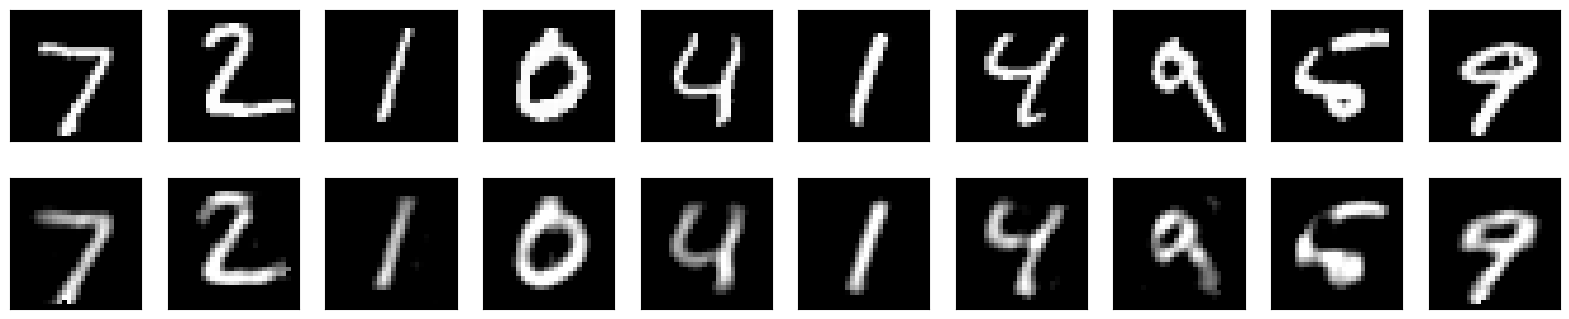

In [ ]:

import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # display original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28),vmin=0,vmax=1)
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # display reconstruccion
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28),vmin=0,vmax=1)
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# Limpieza de ruido

In [ ]:
# Creamos datos ruidosos
x_test_nois = x_test + 0.5*np.random.randn(x_test.shape[0],x_test.shape[1])
encoded_imgs = encoder.predict(x_test_nois)
decoded_imgs = decoder.predict(encoded_imgs)

313/313 [==============================] - 0s 1ms/step


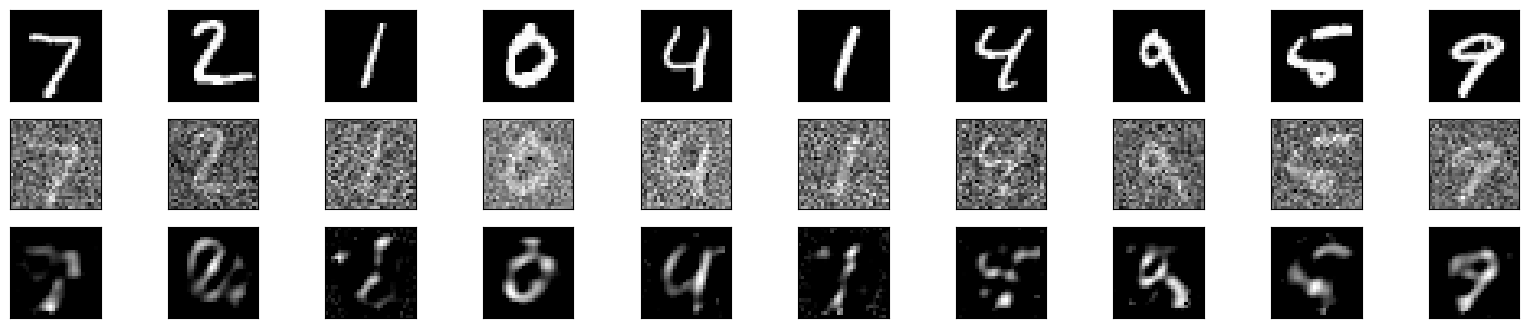

In [ ]:
import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Originales
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Ruidosos
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_nois[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstruccion
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# Detección de anomalias

## Ejemplo con los datos ruidosos

In [ ]:
import numpy as np
# calculamos el error en los datos normales y ruidosos

ncoded_imgs = encoder.predict(x_test_nois)
x_test_nois_pred = decoder.predict(encoded_imgs)

error_nois = np.mean(np.abs(x_test_nois-x_test_nois_pred)**2,tuple(range(1, x_test_nois.ndim)))


x_test_pred = autoencoder.predict(x_test)

error_tes = np.mean(np.abs(x_test-x_test_pred)**2,tuple(range(1, x_test_pred.ndim)))


313/313 [==============================] - 1s 2ms/step


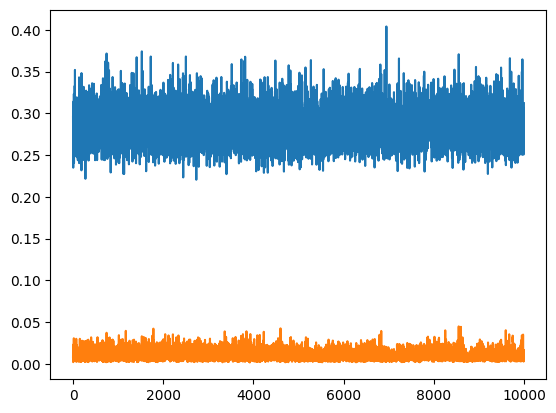

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure
plt.plot(error_nois)
plt.plot(error_tes)


## Ejemplo inventado

In [ ]:
import numpy as np

X_test_anom = x_test.copy()


#Distintos tipos de anomalias

# Zero
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))*0

# Max
#X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))*x_test.max()

# Negativo
X_test_anom[1000,:] = np.ones((1,X_test_anom.shape[1]))-X_test_anom[1000,:]

# Multiplicado
#X_test_anom[1000,:] = 1.5*X_test_anom[1000,:]

# Ruido
#X_test_anom[1000,:] = X_test_anom[1000,:] + 0.5*np.random.randn(1,X_test_anom.shape[1])

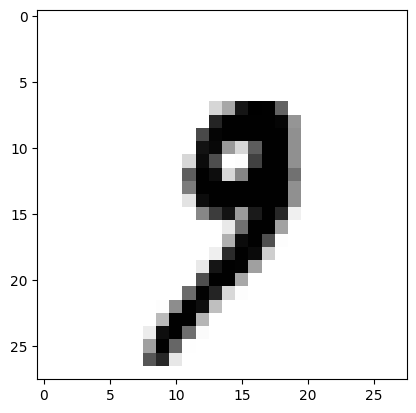

In [ ]:
plt.imshow(np.reshape(X_test_anom[1000,:],(28,28)))

In [ ]:

# calculamos el error en los datos reconstruidos

X_test_anom_pred = autoencoder.predict(X_test_anom)

error_tes = np.mean(np.abs(X_test_anom-X_test_anom_pred)**2,axis = 1)


In [ ]:
error_tes[1000]

0.86767024

In [ ]:
error_tes[1]

0.011222052

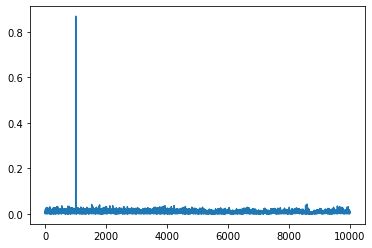

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure
plt.plot(error_tes)
